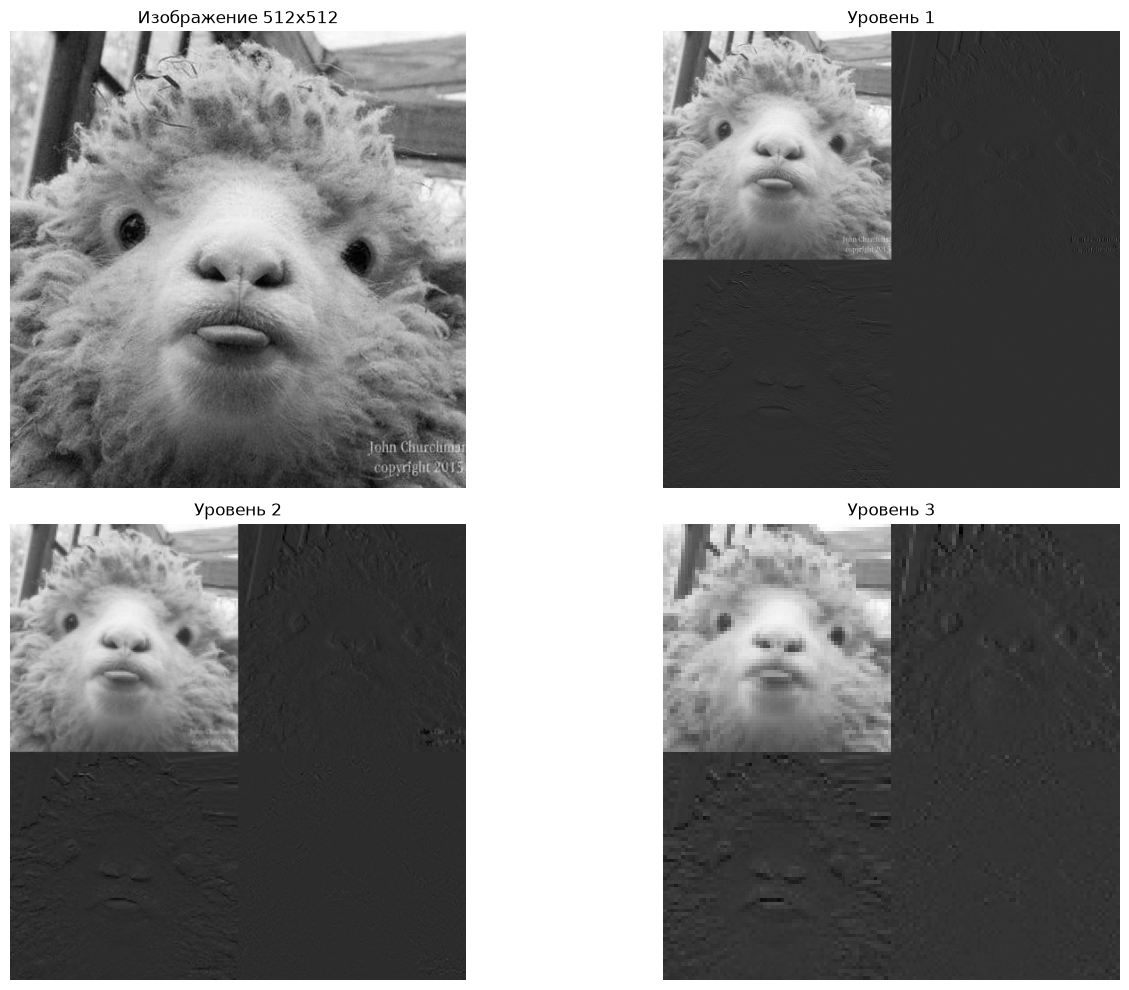

In [4]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('sheep.jpg', cv.IMREAD_GRAYSCALE)

def get_haar_pyramid(image, levels=3):
    img_float = image.astype(np.float32)

    pyramid = []
    
    current = img_float.copy()
    
    for i in range(levels):
        h, w = current.shape
        
        even = current[:, 0::2]
        odd = current[:, 1::2]
        approx = (even + odd) / np.sqrt(2)
        detail = (even - odd) / np.sqrt(2)
        row_trans = np.hstack((approx, detail))
        
        even = row_trans[0::2, :]
        odd = row_trans[1::2, :]
        approx = (even + odd) / np.sqrt(2)
        detail = (even - odd) / np.sqrt(2)
        col_trans = np.vstack((approx, detail))
        
        pyramid.append(col_trans)
        
        current = col_trans[:h//2, :w//2]
        
    return pyramid

levels = 3
pyramid_results = get_haar_pyramid(img, levels)

plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Изображение 512x512')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(pyramid_results[0], cmap='gray')
plt.title('Уровень 1')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(pyramid_results[1], cmap='gray')
plt.title('Уровень 2')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(pyramid_results[2], cmap='gray')
plt.title('Уровень 3')
plt.axis('off')

plt.tight_layout()
plt.show()